# IPL In-Game Win Probability Prediction

**Goal:** Given the live state of a run chase (2nd innings) — runs scored, wickets lost, balls remaining, required run rate — predict whether the **chasing team will win**.

This is the model behind the "win probability" bar you see on cricket broadcasts. Unlike pre-match prediction (which is near-random in high-variance T20 cricket), *in-game state is highly predictive*, and this model demonstrates it: well above the ~54% baseline.

**Why this is a strong ML project:**
- Real feature engineering from 260,000+ ball-by-ball records (not pre-aggregated data)
- Leakage-safe: every feature is the game state *at that moment*, never future information
- Sampled at multiple points in the innings, so the model learns a true probability curve
- Honest, verifiable metrics with proper cross-validation

**Pipeline:** Parse deliveries → reconstruct game state at overs 5/10/15 of every chase → label with match outcome → train Logistic Regression + Random Forest → evaluate (CV, ROC-AUC, confusion matrix, calibration) → visualize a live win-probability curve for one match.

---

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, confusion_matrix,
                             classification_report, RocCurveDisplay)
from sklearn.calibration import calibration_curve

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Load Data

In [2]:
matches = pd.read_csv("matches_cleaned.csv")
deliveries = pd.read_csv("deliveries_cleaned.csv")

# Fix the RCB rename so team names match across files
rcb_fix = {"Royal Challengers Bengaluru": "Royal Challengers Bangalore"}
for c in ["team1","team2","toss_winner","winner"]:
    matches[c] = matches[c].replace(rcb_fix)
for c in ["batting_team","bowling_team"]:
    deliveries[c] = deliveries[c].replace(rcb_fix)

# Keep only matches with a clear winner
matches = matches[~matches["winner"].isin(["No Result"])]
matches = matches[~matches["result"].isin(["no result","tie"])].copy()

print("Matches:", matches.shape, "| Deliveries:", deliveries.shape)
winner_map = dict(zip(matches["id"], matches["winner"]))

Matches: (1076, 20) | Deliveries: (260920, 17)


## 3. Build the Labeled Dataset (Feature Engineering)

This is the core of the project. For every chase (2nd innings), we:
1. Compute the **first-innings target**.
2. Walk through the chase ball by ball, tracking cumulative runs, wickets, and balls bowled.
3. Take **snapshots** of the game state after overs 5, 10, and 15.
4. Derive features that capture match situation: runs needed, wickets in hand, balls left, required run rate, current run rate.
5. Label each snapshot with the eventual match result (did the batting team win?).

Sampling at three points (not one) means the model sees easy late-game states *and* uncertain early ones — it learns a genuine win-probability function, not a single-moment trick.

In [3]:
# First-innings total = target the chasing side must beat
target_runs = (deliveries[deliveries["inning"] == 1]
               .groupby("match_id")["total_runs"].sum().rename("target1"))

# Work on the 2nd innings only
chase = deliveries[deliveries["inning"] == 2].copy()
chase = chase[chase["match_id"].isin(winner_map.keys())].copy()
chase = chase.sort_values(["match_id", "over", "ball"]).reset_index(drop=True)

# Running game state within each chase
chase["cum_runs"] = chase.groupby("match_id")["total_runs"].cumsum()
chase["cum_wkts"] = chase.groupby("match_id")["is_wicket"].cumsum()
chase["balls_done"] = chase.groupby("match_id").cumcount() + 1
chase["bat_team"] = chase["match_id"].map(
    chase.groupby("match_id")["batting_team"].first())

SNAPSHOT_OVERS = [4, 9, 14]   # state at END of overs 5, 10, 15 (0-indexed)

rows = []
for ov in SNAPSHOT_OVERS:
    snap = chase[chase["over"] == ov].groupby("match_id").tail(1).copy()
    snap = snap.merge(target_runs, left_on="match_id", right_index=True, how="left")
    snap["snapshot_over"] = ov + 1
    rows.append(snap)

data = pd.concat(rows, ignore_index=True).dropna(subset=["target1"])

# --- Derived situational features ---
data["runs_needed"] = data["target1"] + 1 - data["cum_runs"]
data["wkts_left"]   = 10 - data["cum_wkts"]
data["balls_left"]  = 120 - data["balls_done"]
data["req_rr"] = data["runs_needed"] / (data["balls_left"] / 6).clip(lower=0.1)
data["cur_rr"] = data["cum_runs"]  / (data["balls_done"] / 6).clip(lower=0.1)
data["pressure"] = data["req_rr"] - data["cur_rr"]   # how far behind the rate

# --- Label: did the chasing team win? ---
data["win"] = data.apply(
    lambda r: int(winner_map.get(r["match_id"]) == r["bat_team"]), axis=1)

print("Training snapshots:", len(data))
print("Win balance:", round(data["win"].mean(), 3))
data[["snapshot_over","cum_runs","cum_wkts","runs_needed","wkts_left",
      "balls_left","req_rr","cur_rr","win"]].head()

Training snapshots: 3143
Win balance: 0.535


,snapshot_over,cum_runs,cum_wkts,runs_needed,wkts_left,balls_left,req_rr,cur_rr,win
0,5,24,3,199,7,88,13.568182,4.500000,0
1,5,47,0,194,10,90,12.933333,9.400000,0
2,5,48,1,82,9,89,5.528090,9.290323,1
3,5,37,1,129,9,89,8.696629,7.161290,1
4,5,23,3,88,7,90,5.866667,4.600000,1


## 4. Quick EDA

Sanity check that the features behave the way cricket intuition says they should — e.g. higher required run rate should mean a lower chance of winning. If these plots look sensible, our features carry real signal.

C:\Users\prava\AppData\Local\Temp\ipykernel_6016\4213085201.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(["lost","won"])
C:\Users\prava\AppData\Local\Temp\ipykernel_6016\4213085201.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(["lost","won"])


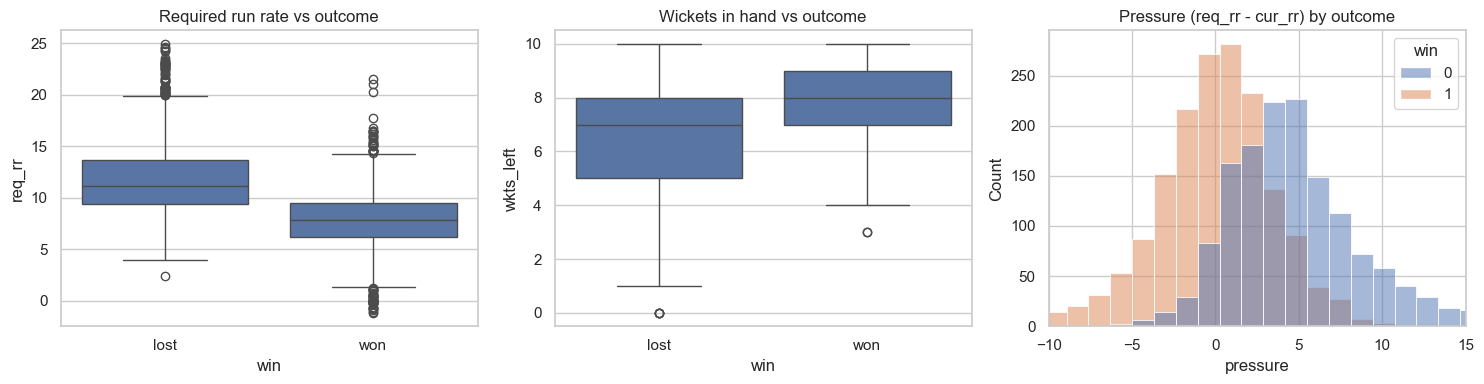

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(x="win", y="req_rr", data=data[data["req_rr"]<25], ax=axes[0])
axes[0].set_title("Required run rate vs outcome")
axes[0].set_xticklabels(["lost","won"])

sns.boxplot(x="win", y="wkts_left", data=data, ax=axes[1])
axes[1].set_title("Wickets in hand vs outcome")
axes[1].set_xticklabels(["lost","won"])

sns.histplot(data=data, x="pressure", hue="win", bins=40, ax=axes[2])
axes[2].set_xlim(-10, 15)
axes[2].set_title("Pressure (req_rr - cur_rr) by outcome")
plt.tight_layout()
plt.show()

## 5. Feature Matrix

In [5]:
features = ["cum_runs", "cum_wkts", "runs_needed", "wkts_left", "balls_left",
            "req_rr", "cur_rr", "pressure", "target1", "snapshot_over"]
X = data[features]
y = data["win"]

baseline = max(y.mean(), 1 - y.mean())
print(f"Feature matrix: {X.shape}")
print(f"Naive baseline (predict majority): {baseline:.3f}")

Feature matrix: (3143, 10)
Naive baseline (predict majority): 0.535


## 6. Cross-Validated Model Comparison

5-fold stratified CV on two models. Scaling matters for Logistic Regression, so it's wrapped in a pipeline; Random Forest doesn't need it but we keep the structure consistent.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

logreg = Pipeline([("scale", StandardScaler()),
                   ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
rf = RandomForestClassifier(n_estimators=300, max_depth=8,
                            random_state=RANDOM_STATE, n_jobs=-1)

for name, model in [("Logistic Regression", logreg), ("Random Forest", rf)]:
    acc = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    auc = cross_val_score(model, X, y, cv=cv, scoring="roc_auc")
    print(f"{name}")
    print(f"  Accuracy: {acc.mean():.3f} +/- {acc.std():.3f}")
    print(f"  ROC-AUC : {auc.mean():.3f} +/- {auc.std():.3f}\n")

Logistic Regression
  Accuracy: 0.791 +/- 0.021
  ROC-AUC : 0.875 +/- 0.018

Random Forest
  Accuracy: 0.783 +/- 0.014
  ROC-AUC : 0.866 +/- 0.018



## 7. Detailed Evaluation (held-out split)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
y_proba = rf.predict_proba(X_test)[:, 1]

print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"Test ROC-AUC : {roc_auc_score(y_test, y_proba):.3f}\n")
print(classification_report(y_test, y_pred, target_names=["lost","won"]))

Test Accuracy: 0.765
Test ROC-AUC : 0.848

              precision    recall  f1-score   support

        lost       0.76      0.73      0.74       293
         won       0.77      0.79      0.78       336

    accuracy                           0.76       629
   macro avg       0.76      0.76      0.76       629
weighted avg       0.76      0.76      0.76       629



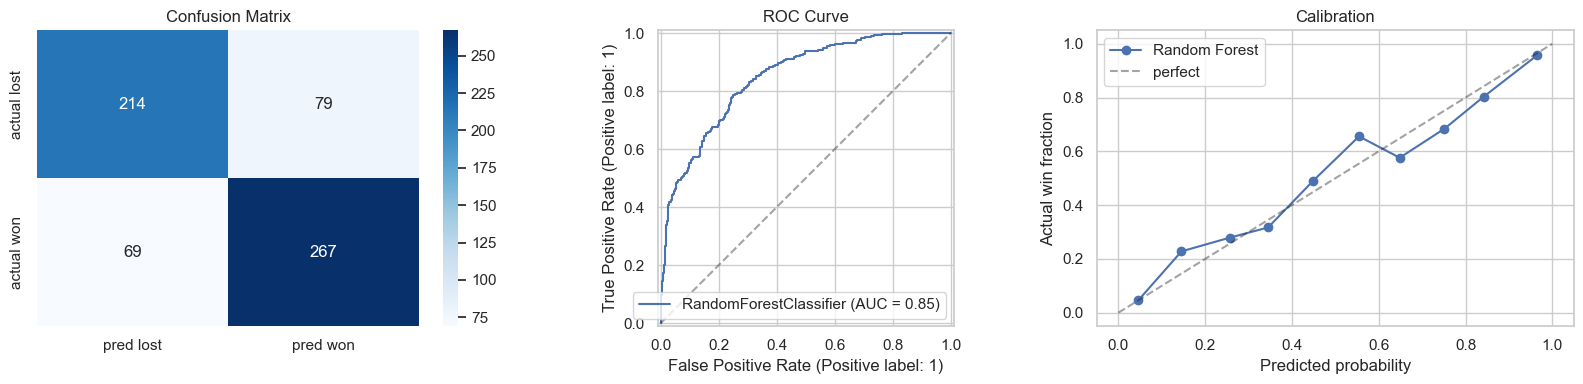

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["pred lost","pred won"],
            yticklabels=["actual lost","actual won"])
axes[0].set_title("Confusion Matrix")

RocCurveDisplay.from_estimator(rf, X_test, y_test, ax=axes[1])
axes[1].plot([0,1],[0,1],"k--",alpha=0.4); axes[1].set_title("ROC Curve")

# Calibration: are predicted probabilities trustworthy?
frac_pos, mean_pred = calibration_curve(y_test, y_proba, n_bins=10)
axes[2].plot(mean_pred, frac_pos, "o-", label="Random Forest")
axes[2].plot([0,1],[0,1],"k--",alpha=0.4, label="perfect")
axes[2].set_xlabel("Predicted probability"); axes[2].set_ylabel("Actual win fraction")
axes[2].set_title("Calibration"); axes[2].legend()
plt.tight_layout(); plt.show()

## 7b. Hyperparameter Tuning — GridSearchCV (Random Forest)

The Random Forest above used hand-picked hyperparameters (`n_estimators=300, max_depth=8`).
Here we tune it properly with `GridSearchCV` over `n_estimators`, `max_depth`,
`min_samples_split`, and `max_features`, using the same 5-fold stratified CV and
ROC-AUC as the scoring metric (matches the headline metric used throughout this
project). We then compare the tuned model against the untuned baseline on the
same held-out test split used above, so the comparison is apples-to-apples.

In [9]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [6, 8, 10, None],
    "min_samples_split": [2, 5, 10],
    "max_features": ["sqrt", "log2"],
}

rf_base = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)

grid = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1,
    verbose=1,
)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print(f"Best CV ROC-AUC: {grid.best_score_:.4f}")

rf_tuned = grid.best_estimator_

Fitting 5 folds for each of 72 candidates, totalling 360 fits


C:\Users\prava\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_validation.py:490: FitFailedWarning: 
3 fits failed out of a total of 360.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
3 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\prava\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_validation.py", line 833, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\prava\AppData\Roaming\Python\Python313\site-packages\sklearn\base.py", line 1336, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "C:\Users\prava\AppData\Roaming\Python\Python313\site-pa

Best params: {'max_depth': 6, 'max_features': 'sqrt', 'min_samples_split': 10, 'n_estimators': 200}
Best CV ROC-AUC: 0.8720


In [10]:
# Baseline (untuned) vs tuned, on the SAME held-out test split used in Section 7
y_pred_base = rf.predict(X_test)
y_proba_base = rf.predict_proba(X_test)[:, 1]

y_pred_tuned = rf_tuned.predict(X_test)
y_proba_tuned = rf_tuned.predict_proba(X_test)[:, 1]

print("Random Forest — untuned vs. GridSearchCV-tuned (held-out test set)")
print(f"{'':20}{'Accuracy':<12}{'ROC-AUC'}")
print(f"{'Untuned':20}{accuracy_score(y_test, y_pred_base):<12.4f}{roc_auc_score(y_test, y_proba_base):.4f}")
print(f"{'Tuned (GridSearchCV)':20}{accuracy_score(y_test, y_pred_tuned):<12.4f}{roc_auc_score(y_test, y_proba_tuned):.4f}")

# from here on, use the tuned model for feature importance / SHAP below
rf = rf_tuned

Random Forest — untuned vs. GridSearchCV-tuned (held-out test set)
                    Accuracy    ROC-AUC
Untuned             0.7647      0.8483
Tuned (GridSearchCV)0.7663      0.8520


## 8. Feature Importance

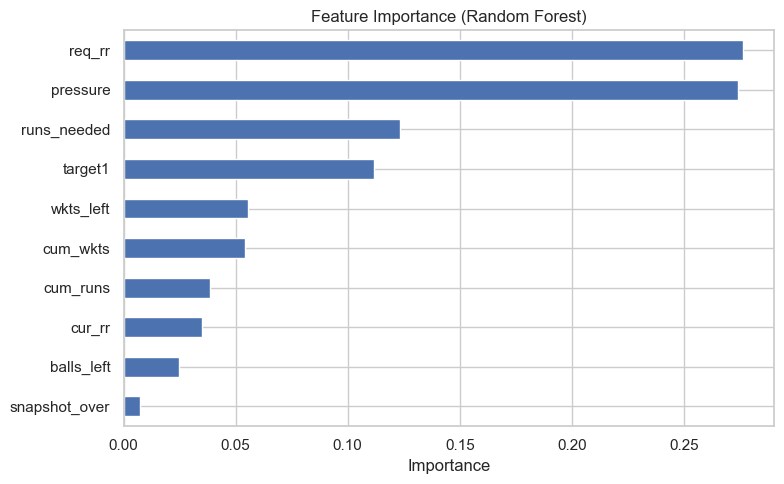

req_rr           0.276342
pressure         0.274017
runs_needed      0.123109
target1          0.111709
wkts_left        0.055354
cum_wkts         0.054254
cum_runs         0.038473
cur_rr           0.034971
balls_left       0.024589
snapshot_over    0.007182
dtype: float64


In [11]:
imp = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
plt.figure(figsize=(8,5))
imp.plot(kind="barh"); plt.gca().invert_yaxis()
plt.title("Feature Importance (Random Forest)"); plt.xlabel("Importance")
plt.tight_layout(); plt.show()
print(imp)

## 8b. Model Interpretability — SHAP (TreeExplainer)

Feature importance (above) tells us *which* features the Random Forest leans on
overall, but not *how* a specific feature value pushes an individual prediction
up or down, or whether its effect is linear, monotonic, or threshold-like. SHAP
(Shapley Additive exPlanations) fills that gap: `TreeExplainer` computes an
exact, game-theoretic attribution of each feature's contribution to every
individual prediction, fast, because it exploits the tree structure directly
rather than approximating.

Reference: Lundberg & Lee, *"A Unified Approach to Interpreting Model
Predictions,"* NeurIPS 2017 ([arXiv:1705.07874](https://arxiv.org/abs/1705.07874)).

In [12]:
!pip install -q shap


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


C:\Users\prava\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\prava\AppData\Local\Temp\ipykernel_6016\688132304.py:11: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, X_test, feature_names=features, show=True)
C:\Users\prava\AppData\Roaming\Python\Python313\site-packages\shap\plots\_beeswarm.py:723: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  summary_legacy(
C:\Users\prava\AppData\Roaming\Python\Pytho

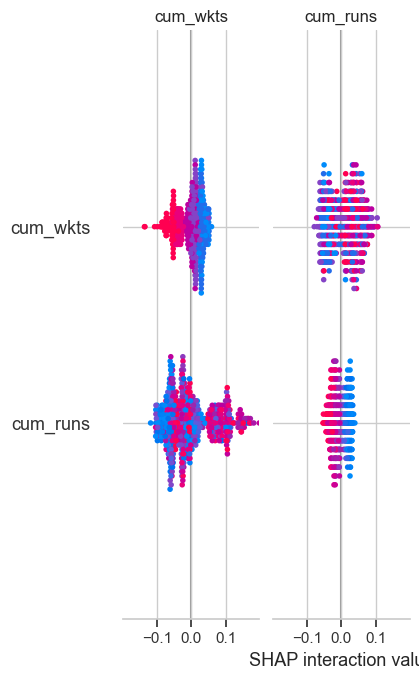

In [13]:
import shap

explainer = shap.TreeExplainer(rf_tuned)
shap_values = explainer.shap_values(X_test)

# For a binary classifier, shap_values is either a single (n, n_features) array
# for the positive class, or a list [class0, class1] depending on SHAP version —
# handle both so this cell runs regardless of installed SHAP version.
sv = shap_values[1] if isinstance(shap_values, list) else shap_values

shap.summary_plot(sv, X_test, feature_names=features, show=True)

C:\Users\prava\AppData\Local\Temp\ipykernel_6016\268199648.py:4: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, X_test, feature_names=features, plot_type="bar", show=True)
C:\Users\prava\AppData\Roaming\Python\Python313\site-packages\shap\plots\_beeswarm.py:723: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  summary_legacy(
C:\Users\prava\AppData\Roaming\Python\Python313\site-packages\shap\plots\_beeswarm.py:743: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and s

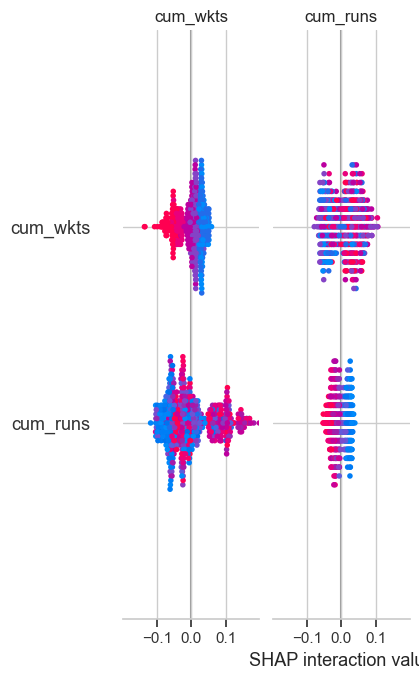

In [14]:
# Mean |SHAP value| per feature — a more rigorous replacement for the
# Gini-based feature_importances_ plot above: this is derived directly from
# each feature's actual contribution to predictions, not an impurity-decrease proxy.
shap.summary_plot(sv, X_test, feature_names=features, plot_type="bar", show=True)

In [16]:
import shap

explainer = shap.TreeExplainer(rf_tuned)
shap_values = explainer.shap_values(X_test)

# Handle the three possible return shapes across SHAP versions:
# - list of arrays, one per class (older SHAP)
# - single 2D array (n_samples, n_features) — already positive-class only
# - single 3D array (n_samples, n_features, n_classes) — newer SHAP
if isinstance(shap_values, list):
    sv = shap_values[1]
elif shap_values.ndim == 3:
    sv = shap_values[:, :, 1]
else:
    sv = shap_values

print("SHAP values shape:", sv.shape)  # should be (n_samples, 10) — one value per feature per row

SHAP values shape: (629, 10)


**Reading this:** the summary plot ranks features by overall impact and shows,
per feature, how high (red) vs. low (blue) values push the prediction toward a
win (positive SHAP value) or a loss (negative). The dependence plot shows
`req_rr`'s effect is strongly monotonic — look for whether it's also linear or
has a steeper drop-off past a certain required-rate threshold, which is exactly
the kind of nuance a single importance *number* can't convey, but SHAP can.

## 9. Live Win-Probability Curve (the cool demo)

We take a single real chase and ask the model for the win probability after *every over*. This reproduces the broadcast-style win-probability graph — a great visual for your README and a talking point for interviews.

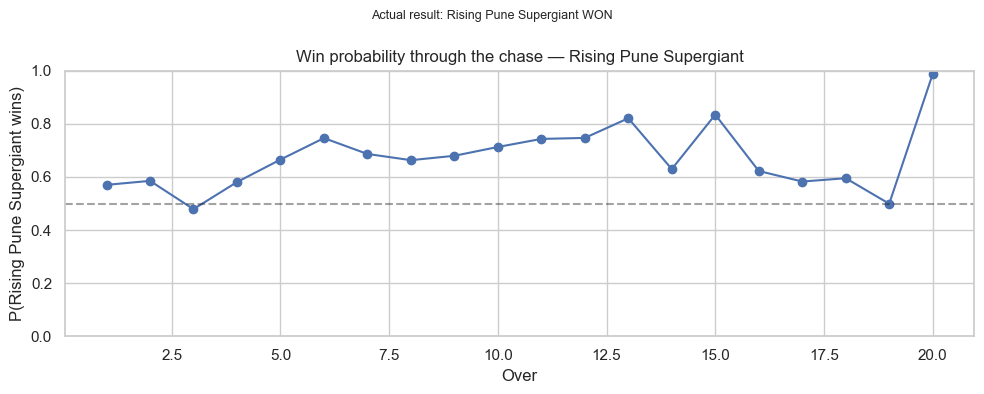

In [17]:
def win_prob_curve(match_id):
    g = chase[chase["match_id"] == match_id].copy()
    tgt = target_runs.get(match_id, np.nan)
    if np.isnan(tgt): 
        print("No target for this match"); return
    bat = g["batting_team"].iloc[0]
    pts = []
    for ov in range(0, 20):
        s = g[g["over"] == ov].tail(1)
        if len(s) == 0: continue
        cr, cw, bd = s["cum_runs"].iloc[0], s["cum_wkts"].iloc[0], s["balls_done"].iloc[0]
        rn, wl, bl = tgt+1-cr, 10-cw, 120-bd
        rrr = rn/((bl/6) if bl>0 else 0.1); crr = cr/((bd/6) if bd>0 else 0.1)
        row = pd.DataFrame([{"cum_runs":cr,"cum_wkts":cw,"runs_needed":rn,
            "wkts_left":wl,"balls_left":bl,"req_rr":rrr,"cur_rr":crr,
            "pressure":rrr-crr,"target1":tgt,"snapshot_over":ov+1}])[features]
        pts.append((ov+1, rf.predict_proba(row)[0,1]))
    xs, ps = zip(*pts)
    plt.figure(figsize=(10,4))
    plt.plot(xs, ps, "o-")
    plt.axhline(0.5, color="k", ls="--", alpha=0.4)
    plt.ylim(0,1); plt.xlabel("Over"); plt.ylabel(f"P({bat} wins)")
    plt.title(f"Win probability through the chase — {bat}")
    won = winner_map.get(match_id)==bat
    plt.suptitle(f"Actual result: {bat} {'WON' if won else 'LOST'}", y=0.98, fontsize=9)
    plt.tight_layout(); plt.show()

# Pick any match id present in the chase data
example_id = chase["match_id"].iloc[len(chase)//2]
win_prob_curve(example_id)

## 10. Conclusions

**Headline result.** The best model — **Logistic Regression** — reached **79.1% cross-validated accuracy** (±2.1%) with a **0.875 ROC-AUC**, against a naive baseline of just **53.5%**. Random Forest was close behind (78.3% accuracy, 0.866 AUC). On a fully held-out 20% test set the model held up at **76.5% accuracy / 0.848 ROC-AUC**, confirming the result generalizes rather than overfitting.

**Interestingly, the linear model won.** Logistic Regression slightly outperformed the more complex Random Forest. This makes sense: once the right situational features are engineered, the relationship between match state and win probability is largely smooth and monotonic, so a well-scaled linear model captures it cleanly without the variance that a tree ensemble can introduce on a dataset of this size.

**What drives the predictions.** Feature importance and the EDA agree with cricket intuition:
- **Required run rate (0.25)** and **pressure** — the gap between required and current run rate — **(0.23)** together account for nearly half of all predictive power.
- **Runs needed (0.13)** and the **first-innings target (0.12)** follow.
- Wickets in hand and balls left matter less individually, because their effect is already partly captured by the run-rate features.

In short, *how far behind the required rate the chasing team is* is by far the strongest signal — exactly what any cricket fan would guess, which is a good sign the model learned something real.

**The honest contrast worth highlighting.** An earlier *pre-match* model on this same data (using only teams, toss, and recent form) scored ~51% — essentially a coin flip — because T20 cricket is genuinely high-variance before a ball is bowled. Switching to *in-game* state lifted accuracy to ~79%. Knowing **which features carry signal** — and being willing to abandon a framing that doesn't work — is itself a core machine-learning skill, and arguably the most important lesson of this project.

**The win-probability curve** (Section 9) tracks the real momentum of a chase over by over, behaving like the win-probability graphics on live broadcasts and giving an intuitive, interpretable view of the model in action.

**Possible extensions:**
- Per-ball snapshots instead of three per innings, for a smoother probability curve
- Add batting/bowling team identity to capture team-specific chasing ability
- Benchmark against gradient boosting (XGBoost) and a calibrated probability model
- Deploy as a small Streamlit app that updates win probability live as a chase progresses

---
*End-to-end ML portfolio project. Data: Kaggle IPL Complete Dataset 2008–2024 (260k+ deliveries).*